## Exploratory Data Analysis

import libraries and settings

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np
import os
import cv2

dataset and class distribution

In [ ]:
# define the dataset path
dataset_path = Path("dataset_8")

# aggregate all image paths and labels
image_paths = list(dataset_path.glob("*/*.jpg"))
data = [(str(path), path.parent.name) for path in image_paths]
df = pd.DataFrame(data, columns=["filepath", "label"])

import os
os.makedirs("output", exist_ok=True)

# count class distribution (saved in output/class_distribution.png)
plt.figure(figsize=(8, 6))
sns.countplot(x='label', data=df, order=df['label'].value_counts().index)
plt.title("Number of Images per Class")
plt.xlabel("Tumor Type")
plt.ylabel("Image Count")
plt.grid(axis='y')
plt.tight_layout()
plt.savefig("output/class_distribution.png") 
plt.close()

In [ ]:
# change working directory and confirm dataset location
%cd /content
print("now cwd:", os.getcwd())
print("here now:", os.listdir())

# you should see 'dataset_8' in the list now
root_dir = 'dataset_8'

/content
now cwd: /content
here now: ['.config', 'drive', 'dataset_8', 'output', 'sample_data']


In [ ]:
root_dir = 'dataset_8'
total_images = 0

# Loop through each subfolder (class)
for subdir in os.listdir(root_dir):
    subdir_path = os.path.join(root_dir, subdir)
    if os.path.isdir(subdir_path):
        image_files = os.listdir(subdir_path)
        num_images = len(image_files)
        total_images += num_images
        print(f"{subdir}: {num_images} images")

print(f"\nTotal images across all classes: {total_images}")

pituitary: 120 images
meningioma: 120 images
glioma: 120 images
notumor: 120 images

Total images across all classes: 480


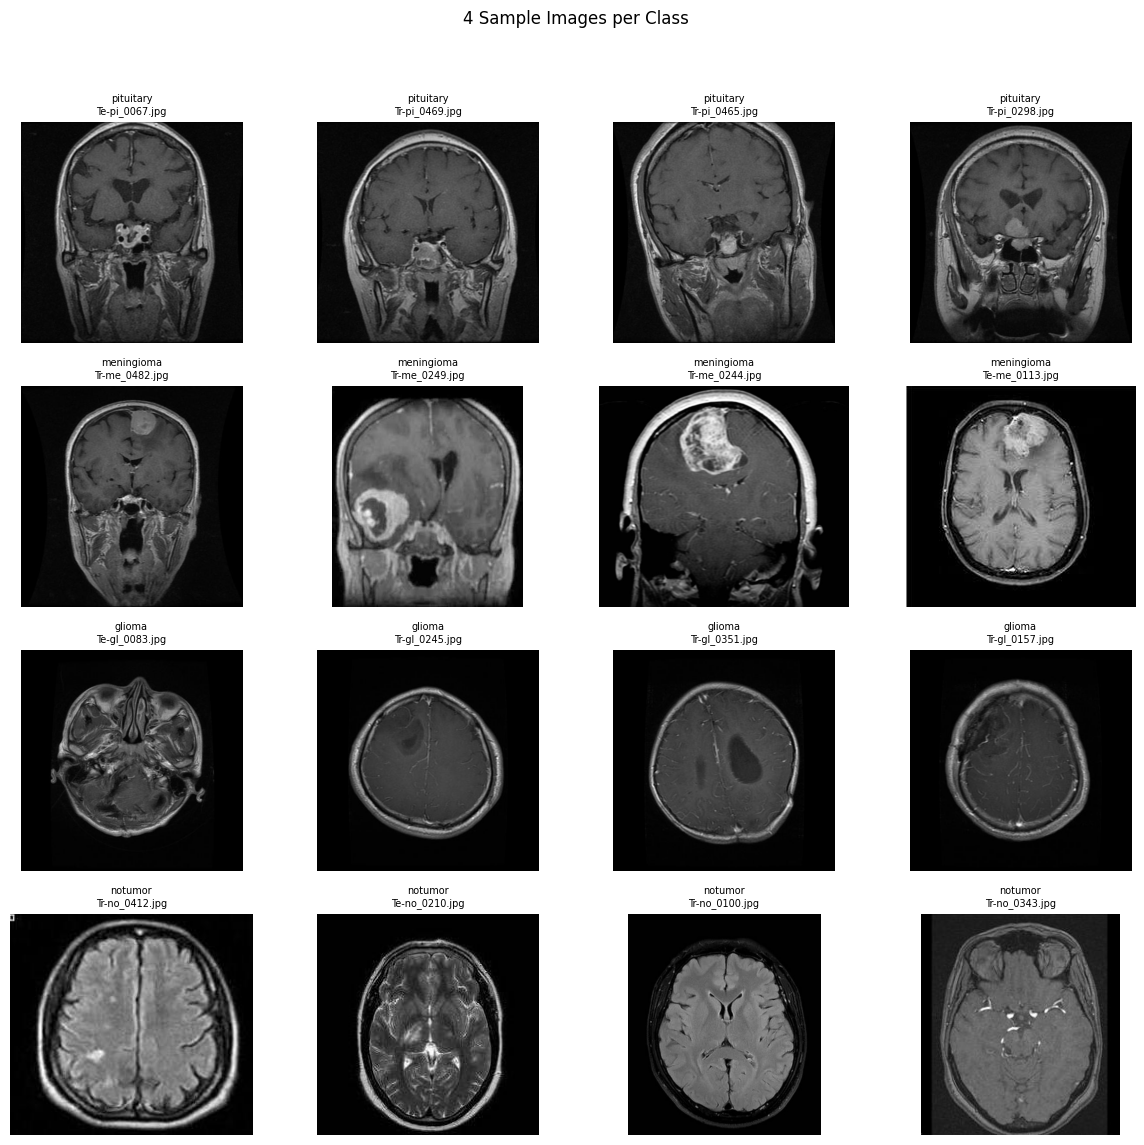

In [ ]:
def show_all_classes_grid(df):
    class_names = df['label'].unique()
    plt.figure(figsize=(12, 12))

    img_count = 0
    for class_name in class_names:
        class_images = df[df['label'] == class_name]['filepath'].sample(4)
        for img_path in class_images:
            img_path = Path(img_path)
            img = cv2.imread(str(img_path))

            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                plt.subplot(4, 4, img_count + 1)
                plt.imshow(img)
                plt.title(f"{class_name}\n{img_path.name}", fontsize=7)
                plt.axis('off')
                img_count += 1

            if img_count >= 16:
                break
        if img_count >= 16:
            break

    plt.suptitle("4 Sample Images per Class", fontsize=12)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

show_all_classes_grid(df)

In [ ]:
# check image shapes
df['shape'] = df['filepath'].apply(lambda x: cv2.imread(str(x)).shape if cv2.imread(str(x)) is not None else None)

# count unique shapes
print(df['shape'].value_counts())

shape
(512, 512, 3)    317
(225, 225, 3)     14
(236, 236, 3)     11
(442, 442, 3)      5
(630, 630, 3)      5
                ... 
(290, 236, 3)      1
(449, 359, 3)      1
(250, 201, 3)      1
(664, 550, 3)      1
(454, 442, 3)      1
Name: count, Length: 106, dtype: int64


dataset has 106 unique image sizes. resize all images during pre-processing (either 512x512 or 224x224)

In [ ]:
def compute_stats(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return pd.Series({
        'mean_intensity': np.mean(img),
        'std_intensity': np.std(img)
    }) if img is not None else pd.Series({'mean_intensity': None, 'std_intensity': None})

df[['mean_intensity', 'std_intensity']] = df['filepath'].apply(compute_stats)

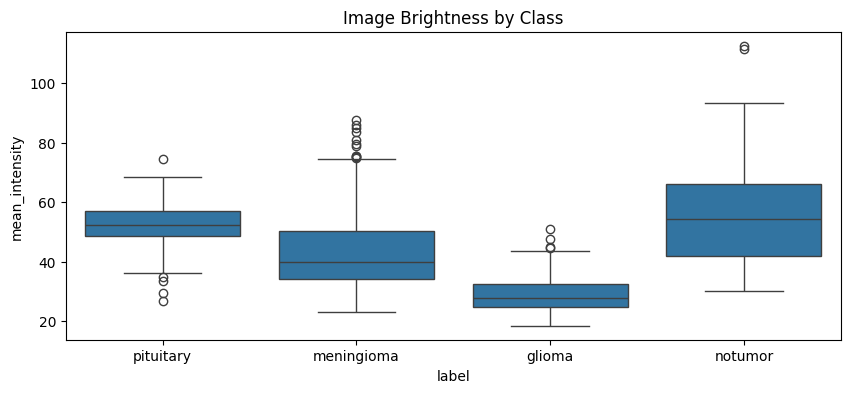

In [ ]:
# image brightness analysis
plt.figure(figsize=(10, 4))
sns.boxplot(x='label', y='mean_intensity', data=df)
plt.title('Image Brightness by Class')
plt.show()

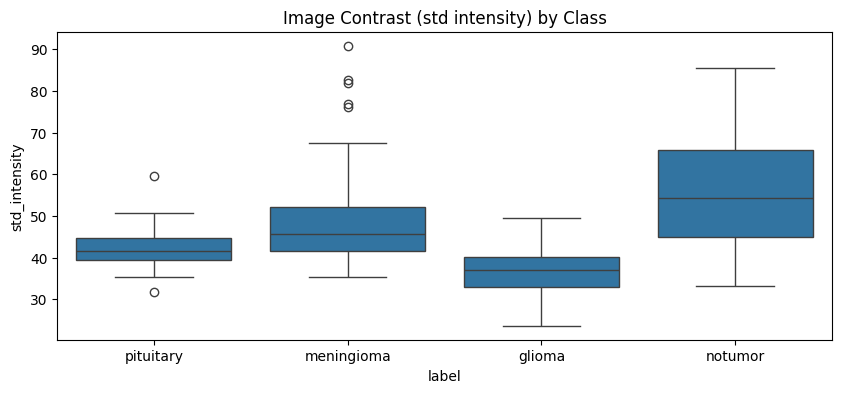

In [ ]:
# image contrast by standard deviation of pixel intensity
plt.figure(figsize=(10, 4))
sns.boxplot(x='label', y='std_intensity', data=df)
plt.title('Image Contrast (std intensity) by Class')
plt.show()

In [ ]:
def is_image_valid(path):
    try:
        img = cv2.imread(str(path))
        return img is not None
    except:
        return False

df['valid'] = df['filepath'].apply(is_image_valid)
print(df['valid'].value_counts())

valid
True    480
Name: count, dtype: int64


Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best RF params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
              precision    recall  f1-score   support

      glioma       1.00      0.88      0.93        24
  meningioma       0.77      0.71      0.74        24
     notumor       0.82      0.96      0.88        24
   pituitary       0.84      0.88      0.86        24

    accuracy                           0.85        96
   macro avg       0.86      0.85      0.85        96
weighted avg       0.86      0.85      0.85        96



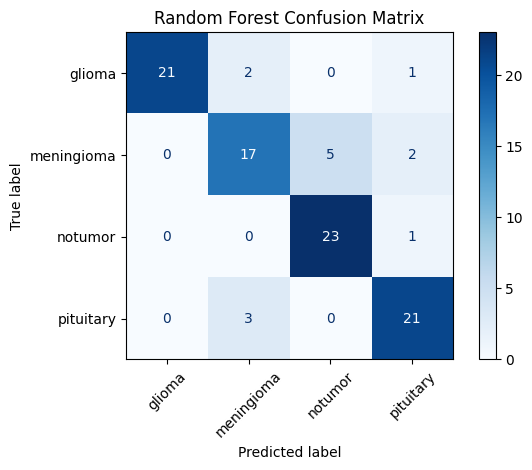

In [10]:
# 1) Imports
import cv2
import numpy as np
import pandas as pd
from skimage.feature import hog
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# 2) HOG feature extractor
def extract_hog(path, resize=(128,128)):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, resize)
    features = hog(
        img,
        orientations=9,
        pixels_per_cell=(8,8),
        cells_per_block=(2,2),
        block_norm='L2-Hys',
        feature_vector=True
    )
    return features

# 3) Build feature matrix and label vector
features = []
for fp in df['filepath']:
    features.append(extract_hog(fp))
X = np.stack(features)
le = LabelEncoder()
y = le.fit_transform(df['label'])   # e.g. {‘glioma’:0, …}

# 4) Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# 5) Scale features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

# 6) RF grid search
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    n_jobs=-1,
    verbose=1
)
rf.fit(X_train, y_train)
print("Best RF params:", rf.best_params_)

# 7) evaluate
y_pred = rf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 8) confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=le.classes_)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()
